# Recovery grid — L(C) vs L(N, D), full vs window

One shared figure with **two rows**: `L(C)` (form `L0`) on top, `L(N, D)` (form `chinchilla3`) on the
bottom. Each row is the same strip of panels as the `bo_ei_recovery` summary figure — coefficient
recovery for a few coefficients, the held-out frontier MSE `MSE_Π(G_held)(L̂_θ)`, and the envelope-set
coverage — with both arms overlaid (**full** = whole pool every step, **window** = growing slab) and
the same solid = *obs + fantasized* / dashed = *observed* convention. A single legend sits below.

Each row reads its runs from its own experiment folder and uses **its own** recipe (selection, split
axis, held-out fraction, arm filenames), so the two forms need not share a pool split:
- top: `../L(C)/runs`  — form `L0`, EI, split on `C`, held-out 0.5, arms `bo_ei_full` / `bo_ei`.
- bottom: `../L(N,D)/runs`  — form `chinchilla3`, random, split on `N`, held-out 0.1, arms
  `cwindow_full` / `cwindow_curriculum_bwd` (the colleague's `cwindow_*` recipe). A **placeholder**
  until those runs exist; the row renders as a labelled placeholder when its runs are missing.

## 0 · Setup + style

In [1]:
import os, sys, json, glob
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%config InlineBackend.figure_format = "retina"

REPO = Path.cwd().resolve()
while not (REPO / "main.py").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from core.forms import PARAMETRIC_FORMS
from core.utils.data import split_search_space
from scaling.utils import get_pareto_frontier
from core.fitting import build_fit
from core.pipelines._common import mse_on_frontier

LEGEND_FONTSIZE = 21



mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": LEGEND_FONTSIZE,
    "axes.titlesize": LEGEND_FONTSIZE, 
    "axes.labelsize": LEGEND_FONTSIZE,
    "xtick.labelsize": LEGEND_FONTSIZE - 5, 
    "ytick.labelsize": LEGEND_FONTSIZE - 5, 
    "legend.fontsize": LEGEND_FONTSIZE,
    "axes.linewidth": 0.6, "lines.linewidth": 1.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.minor.size": 0, "ytick.minor.size": 0,
    "figure.dpi": 200, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
print("repo:", REPO)

repo: /Users/swagatam/Desktop/oellm/surrogate_based_scaling_laws


## 1 · Configuration

`FORMS` defines the two rows. Each entry carries its own recipe: the parametric `form`, the `run_dir`,
the coefficient panels (`params`, `COEF_COLS` of them so the grid is rectangular), the `arms` (filename
+ colour + label), and the pool/held-out split (`split_axis`, `held_out_frac`) used to build that form's
envelope set and held-out frontier. The two arms share colours/labels (**full** blue, **window**
vermillion) but may differ in filename between forms.

In [3]:
EXP       = REPO / "experiments" / "workshop_result"
OUT_DIR   = EXP / "analysis" / "out"; OUT_DIR.mkdir(parents=True, exist_ok=True)
DATASET   = "oellm_english"
CSV       = REPO / "data" / DATASET / "preprocessed" / f"{DATASET}.csv"
SEEDS     = list(range(10))
COEF_COLS = 3                                     # coefficient panels per row (kept equal across rows)
COEF_YMAX = {"A": 1e8}                            # optional log-y caps on coefficient regret panels
PANEL_W, PANEL_H = 3.6, 3.6                       # per-panel size (a touch wider than tall)

BLUE, VERM = "#0072B2", "#D55E00"                 # Okabe-Ito: full / window
def arms(full_fn, window_fn):                     # arm key -> filename + colour + label
    return {"full": dict(fn=full_fn,   color=BLUE, label="full"),
            "slab": dict(fn=window_fn, color=VERM, label="window")}

# one entry per row. `params` must have COEF_COLS names drawn from the form's interpretable keys.
FORMS = {
    "L(C)":   dict(form="L0",          run_dir=EXP / "L(C)"   / "runs", title=r"$L(C)$",
                   params=["L0", "A", "alpha"],  arms=arms("bo_ei_full", "bo_ei"),
                   split_axis="C", held_out_frac=0.5),
    "L(N,D)": dict(form="chinchilla3", run_dir=EXP / "L(N,D)" / "runs", title=r"$L(N,\,D)$",
                   params=["alpha", "beta", "E"], arms=arms("cwindow_full", "cwindow_curriculum_bwd"),
                   split_axis="N", held_out_frac=0.1),
}

# regret labels |theta_hat - theta_search| for every coefficient either form can show
PLABEL = {
    "L0":    r"$|\hat{E} - \hat{E_t}|$",
    "A":     r"$|\hat{A} - \hat{A_t}|$",
    "alpha": r"$|\hat{\alpha} - \hat{\alpha_t}|$",
    "B":     r"$|\hat{B} - \hat{B_t}|$",
    "beta":  r"$|\hat{\beta} - \hat{\beta_t}|$",
    "E":     r"$|\hat{E} - \hat{E_t}|$",
}
X_LABEL = "cost (FLOPs)"
# MSE_LABEL = r"$\mathrm{MSE}(\hat{L},\, L^*)$"
# MSE_LABEL = r"$\mathrm{MSE}(L^{\!\!\!*},\, L_{\theta}^{\mathrm{search}})$"
MSE_LABEL = r"$\mathrm{MSE}(L^{\!\!\!*},\, L_t)$"
ENV_LABEL = "Envelope recovery"
print("rows:", list(FORMS))

rows: ['L(C)', 'L(N,D)']


## 2 · Load the dataset

The pool/held-out split is per form (§4), so here we only load the raw grid once (`C = 6·N·D`).

In [4]:
df = pd.read_csv(CSV); df["C"] = 6.0 * df["N"] * df["D"]
print("grid points:", len(df))

grid points: 942


In [5]:
df

,N,D,lr,gbsz,loss,C
0,124455168.0,1.200000e+10,0.00025,16,2.656725,8.960772e+18
1,124455168.0,6.000000e+09,0.00025,16,2.721845,4.480386e+18
2,124455168.0,1.200000e+10,0.00025,32,2.656892,8.960772e+18
3,124455168.0,6.000000e+09,0.00025,32,2.729814,4.480386e+18
4,124455168.0,1.200000e+11,0.00050,1024,2.556560,8.960772e+19
...,...,...,...,...,...,...
937,588544000.0,2.000000e+10,0.00400,64,2.406985,7.062528e+19
938,588544000.0,3.000000e+10,0.00400,64,2.380026,1.059379e+20
939,588544000.0,5.000000e+10,0.00400,64,2.348877,1.765632e+20
940,588544000.0,6.000000e+09,0.00400,64,2.513114,2.118758e+19


## 3 · Aggregation helpers

Running incumbent per seed, interpolated onto a shared log-compute grid; median + IQR. The recovery
helpers take a per-form `pool` bundle (its envelope set + frontier), since the split differs by form.

In [6]:
def running_incumbent(vals, signed):
    vals = np.asarray(vals, float)
    if signed:
        out, best = [], vals[0]
        for v in vals:
            if abs(v) < abs(best): best = v
            out.append(best)
        return np.asarray(out)
    return np.minimum.accumulate(vals)

def agg_vs_compute(histories, ycol, signed=False, running=True, npts=80, anchors=None, abs_first=False):
    curves, los, his = [], [], []
    for i, h in enumerate(histories):
        x = h["total_compute_spent"].to_numpy(float)
        y = h[ycol].to_numpy(float)
        if abs_first: y = np.abs(y)
        if anchors is not None:
            x0, y0 = anchors[i]
            x = np.concatenate([[x0], x]); y = np.concatenate([[y0], y])
        if running: y = running_incumbent(y, signed)
        curves.append((x, y)); los.append(x.min()); his.append(x.max())
    lo = min(los) if anchors is not None else max(los)
    C = np.geomspace(lo, min(his), npts)
    stack = np.vstack([np.interp(np.log(C), np.log(x), y) for x, y in curves])
    return C, np.median(stack, 0), np.percentile(stack, 25, 0), np.percentile(stack, 75, 0)

def recovery_curve(h, pool):
    pset = set(pool["PSET"])
    C, frac = h["total_compute_spent"].to_numpy(float), []
    for _, row in h.iterrows():
        frac.append(len(pset & set(int(x) for x in row["acquired_idx"])) / len(pset))
    return C, np.asarray(frac)

def _frontier_idx(C, loss, idx):
    order = np.lexsort((loss, C))
    Cs, ls, ids = C[order], loss[order], idx[order]
    uniq = np.concatenate([[True], Cs[1:] != Cs[:-1]])
    ls, ids = ls[uniq], ids[uniq]
    keep, m = np.zeros(len(ls), bool), np.inf
    for i, l in enumerate(ls):
        if l < m: keep[i] = True; m = l
    return set(int(i) for i in ids[keep])

def fantasized_recovery(run_dir, h, pool):
    sp = pd.read_parquet(run_dir / "surrogate_predictions.parquet")
    pool_df = pool["pool_df"]
    C_pool = pool_df["C"].to_numpy(float); idx_pool = pool_df.index.to_numpy()
    true_loss = pool_df["loss"].to_numpy(float)
    pos = {int(i): k for k, i in enumerate(idx_pool)}; pset = set(pool["PSET"])
    comp = h.set_index("iter")["total_compute_spent"]; xs, ys = [], []
    for it, g in sp.groupby("iter"):
        loss = true_loss.copy()
        p = np.array([pos[int(i)] for i in g["idx"]])
        loss[p] = g["pred_loss"].to_numpy(float)
        fidx = _frontier_idx(C_pool, loss, idx_pool)
        xs.append(float(comp.loc[it])); ys.append(len(fidx & pset) / len(pset) * 100)
    return np.asarray(xs), np.asarray(ys)

def observed_recovery(h, pool):
    C, frac = recovery_curve(h, pool)
    return C, frac * 100.0

def agg_recovery(curves, anchors=None):
    if anchors is not None:
        curves = [(np.concatenate([[a[0]], x]), np.concatenate([[a[1]], y]))
                  for (x, y), a in zip(curves, anchors)]
    los = [x.min() for x, _ in curves]; his = [x.max() for x, _ in curves]
    lo = min(los) if anchors is not None else max(los)
    grid = np.geomspace(lo, min(his), 80)
    stack = np.vstack([np.interp(np.log(grid), np.log(x), y) for x, y in curves])
    return grid, np.median(stack, 0), np.percentile(stack, 25, 0), np.percentile(stack, 75, 0)

## 4 · Load + prepare each form

For every form we build its own pool/held split, locate its runs
(`run_dir/<fn>/<dataset>/<form>/seed_*/<ts>/`), load `history.parquet` + `ref_fits.json`, and
precompute what the plot needs: the envelope set + held-out frontier, the validation reference fit, the
shared init anchor, and the observed-only held-out MSE column (recomputed from `obs_only_params`). A
form with no runs yields `None` — its row is drawn as a placeholder.

In [7]:
def build_pool(cfg):
    pool_df, held_df = split_search_space(df.copy(), held_out_frac=cfg["held_out_frac"], axis=cfg["split_axis"])
    pool_opt = get_pareto_frontier(pool_df, x_name="C", y_name="loss").sort_values("C")
    combined = pd.concat([pool_df, held_df])
    glob_par = get_pareto_frontier(combined, x_name="C", y_name="loss")
    held_front = glob_par.loc[glob_par.index.isin(held_df.index)]
    return dict(pool_df=pool_df, held_df=held_df, PSET=[int(i) for i in pool_opt.index],
                pool_total_C=float(pool_df["C"].sum()), held_front=held_front)

def latest(run_dir, fn, form, seed):
    fs = sorted(glob.glob(str(run_dir / fn / DATASET / form / f"seed_{seed}" / "*" / "history.parquet")))
    return Path(fs[-1]).parent if fs else None

def prepare(cfg):
    """Return a bundle for one form, or None if no runs are present for it yet."""
    form_name, run_dir, A = cfg["form"], cfg["run_dir"], cfg["arms"]
    FORM = PARAMETRIC_FORMS[form_name]
    hist, refs, seeds_ok = {a: {} for a in A}, {a: {} for a in A}, {}
    for a, ac in A.items():
        present = []
        for s in SEEDS:
            d = latest(run_dir, ac["fn"], form_name, s)
            if d is None: continue
            hist[a][s] = pd.read_parquet(d / "history.parquet")
            hist[a][s].attrs["run_dir"] = str(d)
            refs[a][s] = json.loads((d / "ref_fits.json").read_text())
            present.append(s)
        seeds_ok[a] = present
    seeds = sorted(set(seeds_ok["full"]) & set(seeds_ok["slab"]))
    if not seeds:
        return None

    pool = build_pool(cfg)
    val_ref = refs["full"][seeds[0]]["validation"]["interpretable"]   # pool reference (arm/seed-invariant)

    init_info = {}                                                    # shared init anchor per seed
    pset = set(pool["PSET"])
    for s in seeds:
        row0 = hist["full"][s].iloc[0]
        iset = set(int(i) for i in row0["acquired_idx"]) - {int(row0["new_idx"])}
        idf = df.loc[df.index.intersection(sorted(iset))]
        p, _ = build_fit(idf, form_name=form_name, y_name="loss", fit_quality="dense")
        init_info[s] = dict(
            compute=float(idf["C"].sum()),
            interp=FORM.interpretable(np.asarray(p, float)),
            mse=mse_on_frontier(pool["held_front"], FORM, np.asarray(p, float)),
            env_pct=len(pset & iset) / len(pset) * 100.0,
        )

    for a in A:                                                      # obs-only held-out MSE column
        for s in seeds:
            hist[a][s]["law_mse_obs_only_held_out"] = [
                mse_on_frontier(pool["held_front"], FORM, np.asarray(pp, float))
                for pp in hist[a][s]["obs_only_params"]]

    return dict(FORM=FORM, hist=hist, seeds=seeds, arms=A, pool=pool,
                val_ref=val_ref, init_info=init_info)

PREP = {name: prepare(cfg) for name, cfg in FORMS.items()}
for name, p in PREP.items():
    print(f"{name:8s}: " + (f"live ({len(p['seeds'])} seeds, {len(p['pool']['PSET'])} envelope pts, "
                            f"{len(p['pool']['held_front'])} held-out frontier pts)"
                            if p else "placeholder (no runs found)"))

L(C)    : live (10 seeds, 21 envelope pts, 2 held-out frontier pts)
L(N,D)  : placeholder (no runs found)


In [8]:
PREP['L(C)']['arms']

{'full': {'fn': 'bo_ei_full', 'color': '#0072B2', 'label': 'full'},
 'slab': {'fn': 'bo_ei', 'color': '#D55E00', 'label': 'window'}}

## 5 · The two-row grid

`plot_row` draws one form's strip: `COEF_COLS` coefficient-recovery panels, held-out frontier MSE, and
envelope-set coverage. A placeholder form (no runs) is drawn as labelled empty axes. Column headers for
the coefficient panels are per row (the two forms recover different coefficients); the MSE / coverage
headers and the x-axis labels follow the reference layout (top row / bottom row respectively). One
shared horizontal legend sits below the grid.

In [29]:
def regret_anchor(prep, name):
    return [(prep["init_info"][s]["compute"], abs(prep["init_info"][s]["interp"][name] - prep["val_ref"][name]))
            for s in prep["seeds"]]

def mse_anchor(prep):
    return [(prep["init_info"][s]["compute"], prep["init_info"][s]["mse"]) for s in prep["seeds"]]

def env_anchor(prep):
    return [(prep["init_info"][s]["compute"], prep["init_info"][s]["env_pct"]) for s in prep["seeds"]]

def plot_row(axes_row, name, prep, show_mse_env_titles, show_xlabel, show_xlabel_loc=0, make_xlabel_white=False, make_title_white=False):
    
    import matplotlib.ticker as mticker
    from matplotlib.ticker import LogLocator
    
    cfg = FORMS[name]
    coef_axes, ax_mse, ax_env = axes_row[:COEF_COLS], axes_row[-2], axes_row[-1]

    if prep is None:                                     # placeholder row
        for ax, cn in zip(coef_axes, cfg["params"]): ax.set_title(PLABEL[cn])
        if make_title_white:
            for ax, cn in zip(coef_axes, cfg["params"]):
                ax.title.set_color('white')
        if show_mse_env_titles: ax_mse.set_title(MSE_LABEL); ax_env.set_title(ENV_LABEL)
        for ax in axes_row:
            ax.text(0.5, 0.5, "runs pending", transform=ax.transAxes, ha="center", va="center",
                    color="0.6", style="italic")
            ax.set_xticks([]); ax.set_yticks([])
            if show_xlabel: ax.set_xlabel(X_LABEL)
        return

    seeds, A, pool = prep["seeds"], prep["arms"], prep["pool"]
    # coefficient recovery: obs+fantasized (solid) vs observed-only (dashed)
    for ax, cn in zip(coef_axes, cfg["params"]):
        anc = regret_anchor(prep, cn)
        for a, ac in A.items():
            C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], f"regret_val_{cn}",
                                            anchors=anc, abs_first=True)
            ax.plot(C, med, color=ac["color"], lw=1.4, ls="-", zorder=3)
            ax.fill_between(C, lo, hi, color=ac["color"], alpha=0.15, lw=0)
            C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], f"regret_obs_only_val_{cn}",
                                            anchors=anc, abs_first=True)
            ax.plot(C, med, color=ac["color"], lw=1.2, ls="--", zorder=3)
            ax.fill_between(C, lo, hi, color=ac["color"], alpha=0.10, lw=0)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(PLABEL[cn])
        if make_title_white: ax.title.set_color('white')
        # ax.xaxis.set_minor_locator(mticker.NullLocator())
        ax.xaxis.set_major_locator(LogLocator(base=10.0))
        # ax.yaxis.set_minor_locator(mticker.NullLocator())
        ax.yaxis.set_major_locator(LogLocator(base=10.0))
        if cn in COEF_YMAX: ax.set_ylim(top=COEF_YMAX[cn])
        
            

    # held-out frontier MSE: obs+fantasized (solid, logged) vs observed-only (dashed, recomputed)
    anc_mse = mse_anchor(prep)
    for a, ac in A.items():
        C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], "law_mse_held_out", running=False, anchors=anc_mse)
        ax_mse.plot(C, med, color=ac["color"], lw=1.4, ls="-", zorder=3)
        ax_mse.fill_between(C, lo, hi, color=ac["color"], alpha=0.15, lw=0)
        C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], "law_mse_obs_only_held_out", running=False, anchors=anc_mse)
        ax_mse.plot(C, med, color=ac["color"], lw=1.2, ls="--", zorder=3)
        ax_mse.fill_between(C, lo, hi, color=ac["color"], alpha=0.10, lw=0)
    ax_mse.set_xscale("log"); ax_mse.set_yscale("log")
    # ax_mse.xaxis.set_minor_locator(mticker.NullLocator())
    ax_mse.xaxis.set_major_locator(LogLocator(base=10.0))
    # ax_mse.yaxis.set_minor_locator(mticker.NullLocator())
    ax_mse.yaxis.set_major_locator(LogLocator(base=10.0))
    if show_mse_env_titles: ax_mse.set_title(MSE_LABEL)
    if make_title_white: ax_mse.title.set_color('white')

    # envelope-set coverage: obs+fantasized (solid) vs observed (dashed)
    anc_env = env_anchor(prep)

    for a, ac in A.items():
        g, med, q1, q3 = agg_recovery([fantasized_recovery(Path(prep["hist"][a][s].attrs["run_dir"]),
                                                            prep["hist"][a][s], pool) for s in seeds],
                                      anchors=anc_env)
        ax_env.plot(g, med, color=ac["color"], lw=1.5, ls="-", zorder=3)
        ax_env.fill_between(g, q1, q3, color=ac["color"], alpha=0.15, lw=0)
        g, med, q1, q3 = agg_recovery([observed_recovery(prep["hist"][a][s], pool) for s in seeds],
                                      anchors=anc_env)
        ax_env.plot(g, med, color=ac["color"], lw=1.3, ls="--", zorder=3)
        ax_env.fill_between(g, q1, q3, color=ac["color"], alpha=0.10, lw=0)
    ax_env.axvline(pool["pool_total_C"], color="0.4", ls=":", lw=1.0, zorder=2)
    ax_env.set_xscale("log")
    ax_env.set_ylim(0, 101)
    ax_env.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
    # Remove minor ticks on x-axis and set only major ticks at 10^n
    # from matplotlib.ticker import LogLocator
    # ax_env.xaxis.set_minor_locator(mticker.NullLocator())
    ax_env.xaxis.set_major_locator(LogLocator(base=10.0))
    # ax_env.yaxis.set_tick_params(labelrotation=90)
    if show_mse_env_titles: ax_env.set_title(ENV_LABEL)
    if make_title_white: ax_env.title.set_color('white')

    for j, ax in enumerate(axes_row):
        # if show_xlabel and j == show_xlabel_loc: ax.set_xlabel(X_LABEL) # this removes the x-axis label except the one chosen
        if show_xlabel:
            ax.set_xlabel(X_LABEL)
            if make_xlabel_white:
                ax.xaxis.label.set_color('white')
        ax.grid(which="major", ls=":", lw=0.4, alpha=0.4)

In [10]:
# shared full/window/style legend proxies (also used by the standalone L(C) figure below)
LEGEND_HANDLES = [Line2D([], [], color=BLUE, lw=1.6, label="Full"),
                  Line2D([], [], color=VERM, lw=1.6, label="Window"),
                  Line2D([], [], color="0.35", lw=1.5, ls="-",  label="Obs. + fant."),
                  Line2D([], [], color="0.35", lw=1.3, ls="--", label="Obs."),
                #   Line2D([], [], color="0.4",  lw=1.0, ls=":",  label="full pool compute")
                  ]

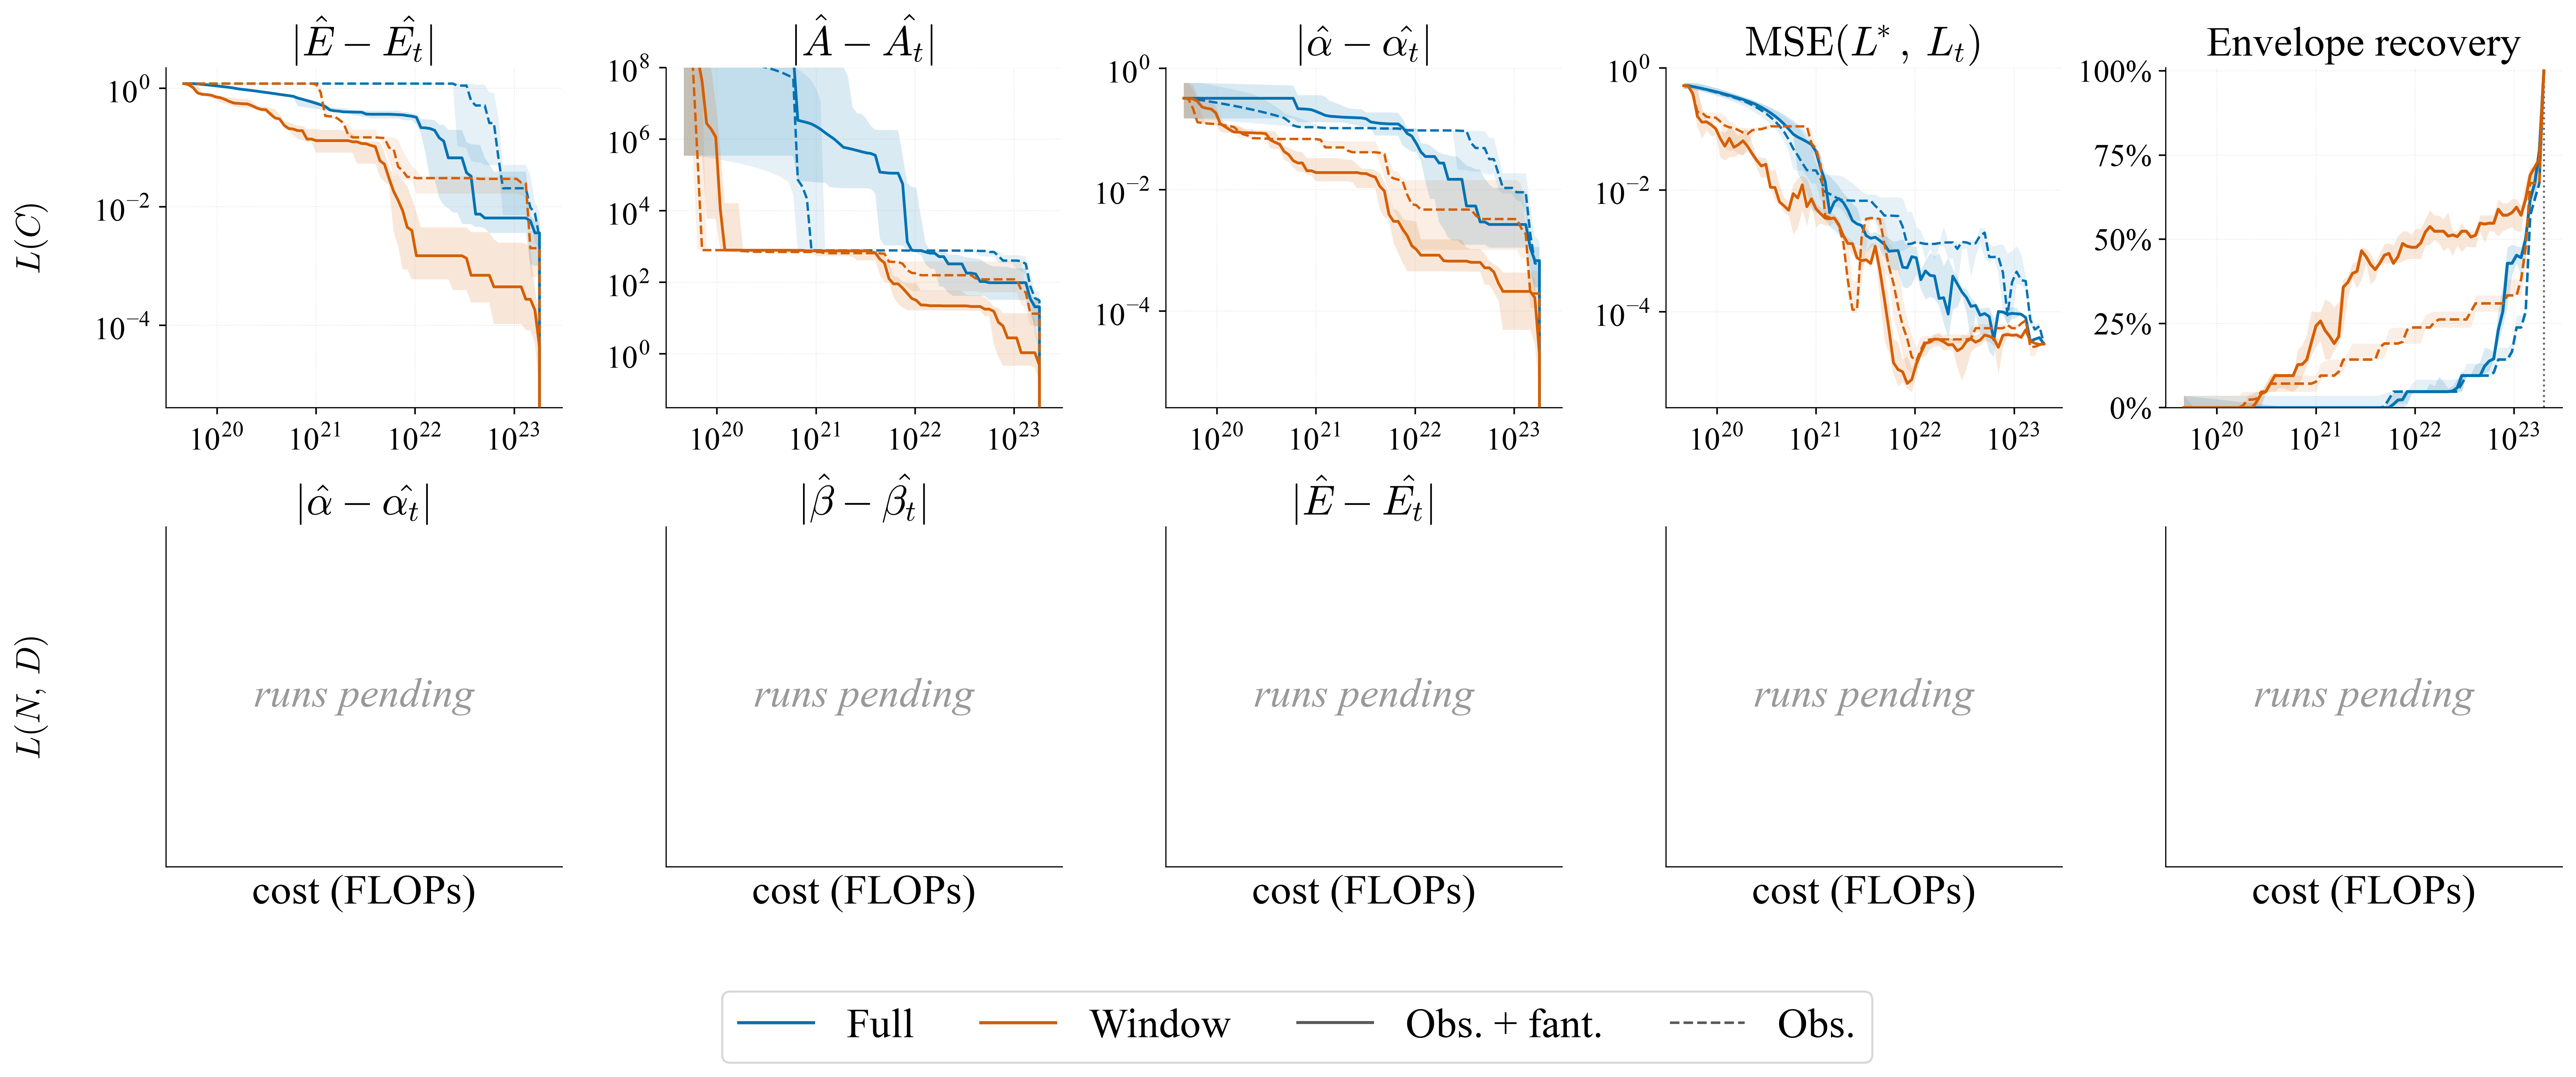

In [11]:
nrows, ncols = len(FORMS), COEF_COLS + 2
fig, axes = plt.subplots(nrows, ncols, figsize=(PANEL_W * ncols, PANEL_H * nrows))
axes = np.atleast_2d(axes)
for i, (name, cfg) in enumerate(FORMS.items()):
    plot_row(axes[i], name, PREP[name], show_mse_env_titles=(i == 0), show_xlabel=(i == nrows - 1))
    axes[i][0].annotate(cfg["title"], xy=(-0.34, 0.5), xycoords="axes fraction",
                        rotation=90, va="center", ha="center", fontsize=17)

# one shared horizontal legend below the grid (explicit proxies so it is drawn even for placeholder rows)
fig.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
           ncol=len(LEGEND_HANDLES), frameon=True, bbox_to_anchor=(0.5, -0.06),
           handlelength=1.8, columnspacing=1.6)
fig.tight_layout(pad=0.4, rect=(0, 0.09, 1, 1))
# fig.savefig(OUT_DIR / "fig_recovery_grid.pdf")
plt.show()

## 6 · L(C) row on its own

The same strip for `L(C)` alone (form `L0`), for slides/paper where only the compute-law row is shown.
Reuses `plot_row`; saves `out/fig_recovery_LC.pdf`.

In [12]:
PANEL_H, PANEL_W

(3.6, 3.6)

In [13]:
LEGEND_HANDLES

In [14]:
PANEL_W, PANEL_H = 3.6, 3.6                    # per-panel size (a touch wider than tall)

In [15]:
# shared full/window/style legend proxies (also used by the standalone L(C) figure below)
LEGEND_HANDLES = [Line2D([], [], color=BLUE, lw=2, label="Full"),
                  Line2D([], [], color=VERM, lw=2, label="Window"),
                  Line2D([], [], color="0.35", lw=2, ls="-",  label="Observed + fantasized"),
                  Line2D([], [], color="0.35", lw=2, ls="--", label="Observed only"),
                #   Line2D([], [], color="0.4",  lw=1.0, ls=":",  label="full pool compute")
                  ]

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


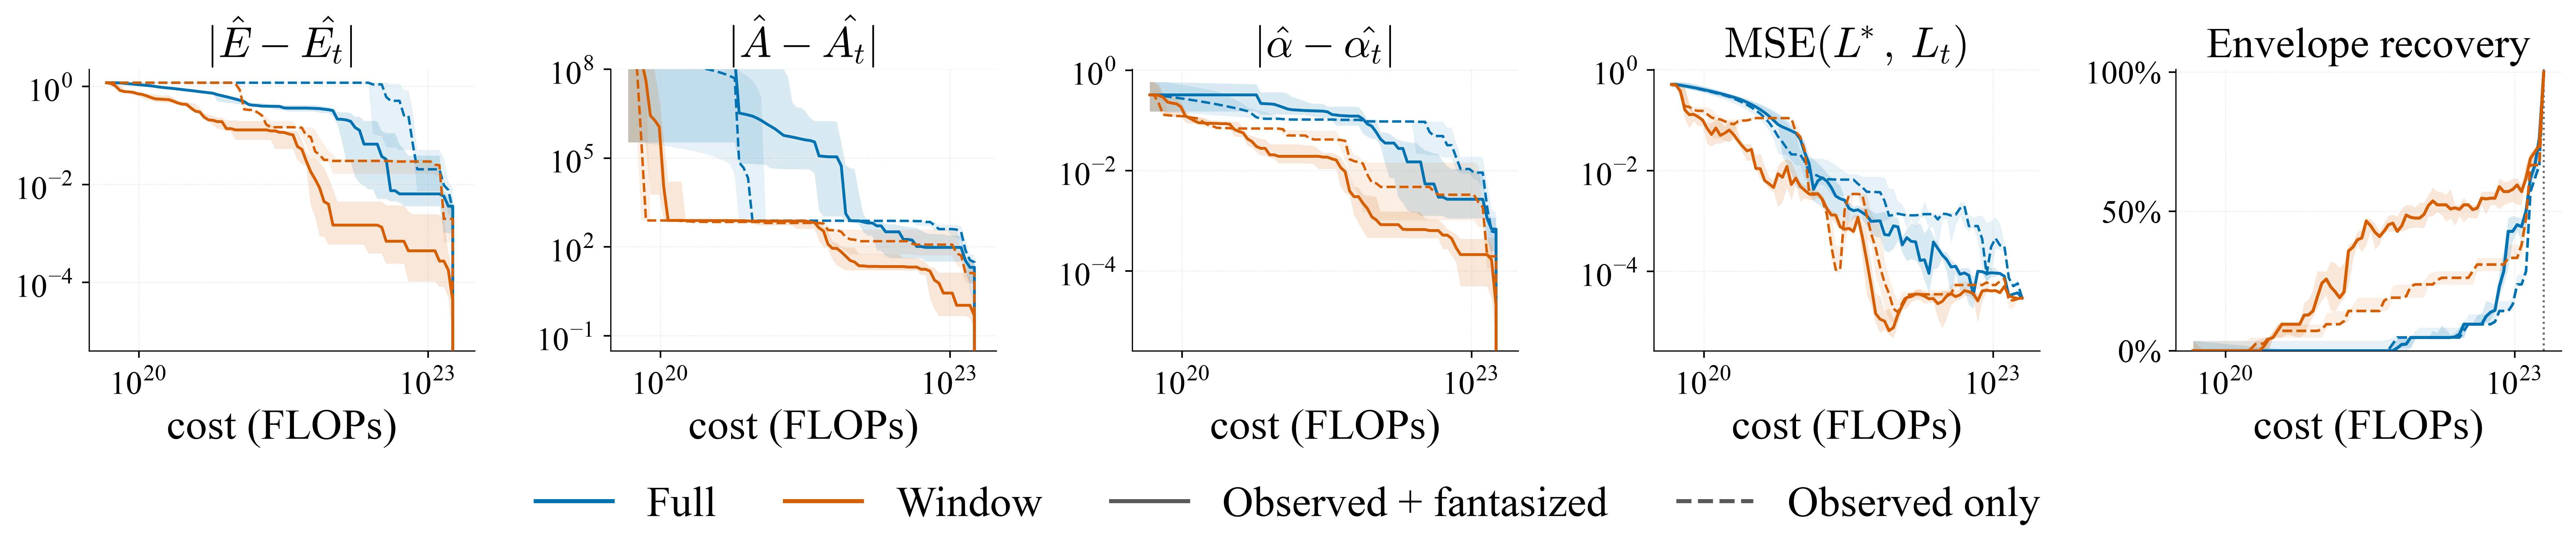

In [16]:
name = "L(C)"
ncols = COEF_COLS + 2
figc, axc = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))
plot_row(axc, name, PREP[name], show_mse_env_titles=True, show_xlabel=True)
# axc[0].annotate(FORMS[name]["title"], xy=(-0.34, 0.5), xycoords="axes fraction",
#                 rotation=90, va="center", ha="center", fontsize=17)
figc.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
            ncol=len(LEGEND_HANDLES), frameon=False, bbox_to_anchor=(0.5, -0.13),
            handlelength=1.8, columnspacing=1.6)
figc.tight_layout(
    # pad=0.4, 
    # rect=(0, 0.12, 1, 1)
    )
figc.savefig(OUT_DIR / "fig_recovery_LC.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()

## For acquisition function: LCB

In [17]:
ABL_CACHE = EXP / "analysis" / "_ablation_cache" / "ablation_acquisition" / "runs"
CFG_LC_LCB = dict(FORMS["L(C)"], run_dir=ABL_CACHE, arms=arms("lcb_full", "af_lcb"))
PREP_LC_LCB = prepare(CFG_LC_LCB)
print("L(C) LCB:", (f"live ({len(PREP_LC_LCB['seeds'])} seeds, "
                     f"{len(PREP_LC_LCB['pool']['PSET'])} envelope pts)"
                     if PREP_LC_LCB else "placeholder (no runs found)"))


L(C) LCB: live (10 seeds, 21 envelope pts)


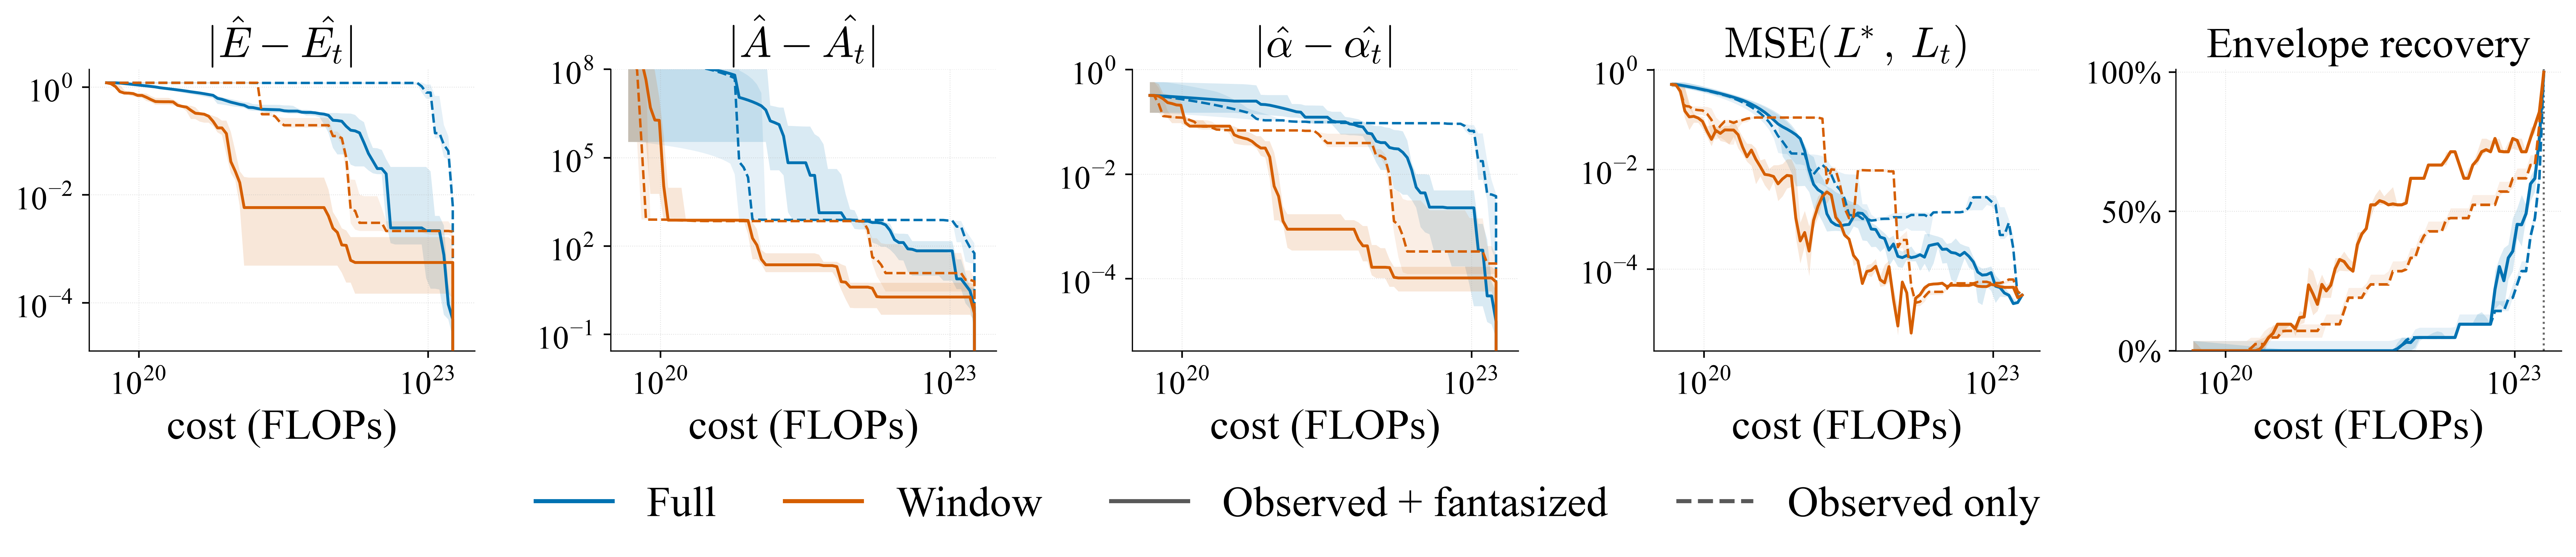

In [18]:
name = "L(C)"
ncols = COEF_COLS + 2
fig_lcb, ax_lcb = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))
plot_row(ax_lcb, name, PREP_LC_LCB, show_mse_env_titles=True, show_xlabel=True, show_xlabel_loc=0)
fig_lcb.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
            ncol=len(LEGEND_HANDLES), frameon=False, bbox_to_anchor=(0.5, -0.13),
            handlelength=1.8, columnspacing=1.6)
fig_lcb.tight_layout()
# fig_lcb.savefig(OUT_DIR / "fig_recovery_LC_lcb.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()

In [20]:
import matplotlib.transforms as mtransforms

def savefig_cropped_bottom(fig, filepath, crop_bottom_inches=0.5, pad_inches=0.0, **kwargs):
    """
    Saves a Matplotlib figure with a specified bottom crop in inches.
    """
    fig.canvas.draw()
    bbox = fig.get_tightbbox(fig.canvas.get_renderer())
    
    cropped_bbox = mtransforms.Bbox.from_extents(
        bbox.x0,
        bbox.y0 + crop_bottom_inches,
        bbox.x1,
        bbox.y1
    )
    
    fig.savefig(filepath, bbox_inches=cropped_bbox, pad_inches=pad_inches, **kwargs)

## Warmstarting data

In [ ]:
DATASET   = "warmstart_surrogate"
CSV       = REPO / "experiments" / "ablation_datasets" / "warmstart" / "warmstart_surrogate.csv"
df = pd.read_csv(CSV)   # C is measured FLOPs (see make_warmstart_input.py)
print("grid points:", len(df), "| C range:", f"{df['C'].min():.2e}", "–", f"{df['C'].max():.2e}")

grid points: 150 | C range: 6.23e+15 – 4.45e+20


In [22]:
# df

In [23]:
ABL_WARMSTART = EXP / "analysis" / "_ablation_cache" / "ablation_datasets" / "warmstart" / "runs"

CFG_LC_WARM = dict(form="L0", run_dir=ABL_WARMSTART, title=r"$L(C)$",
                    params=["L0", "A", "alpha"], arms=arms("full", "window"),
                    split_axis="C", held_out_frac=0.9)   # warmstart uses 0.9 (see warmstart/README.md)

PREP_LC_WARM = prepare(CFG_LC_WARM)
print("L(C) warmstart:", (f"live ({len(PREP_LC_WARM['seeds'])} seeds, "
                          f"{len(PREP_LC_WARM['pool']['PSET'])} envelope pts, "
                          f"{len(PREP_LC_WARM['pool']['held_front'])} held-out frontier pts)"
                          if PREP_LC_WARM else "placeholder (no runs found)"))

L(C) warmstart: live (10 seeds, 14 envelope pts, 3 held-out frontier pts)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


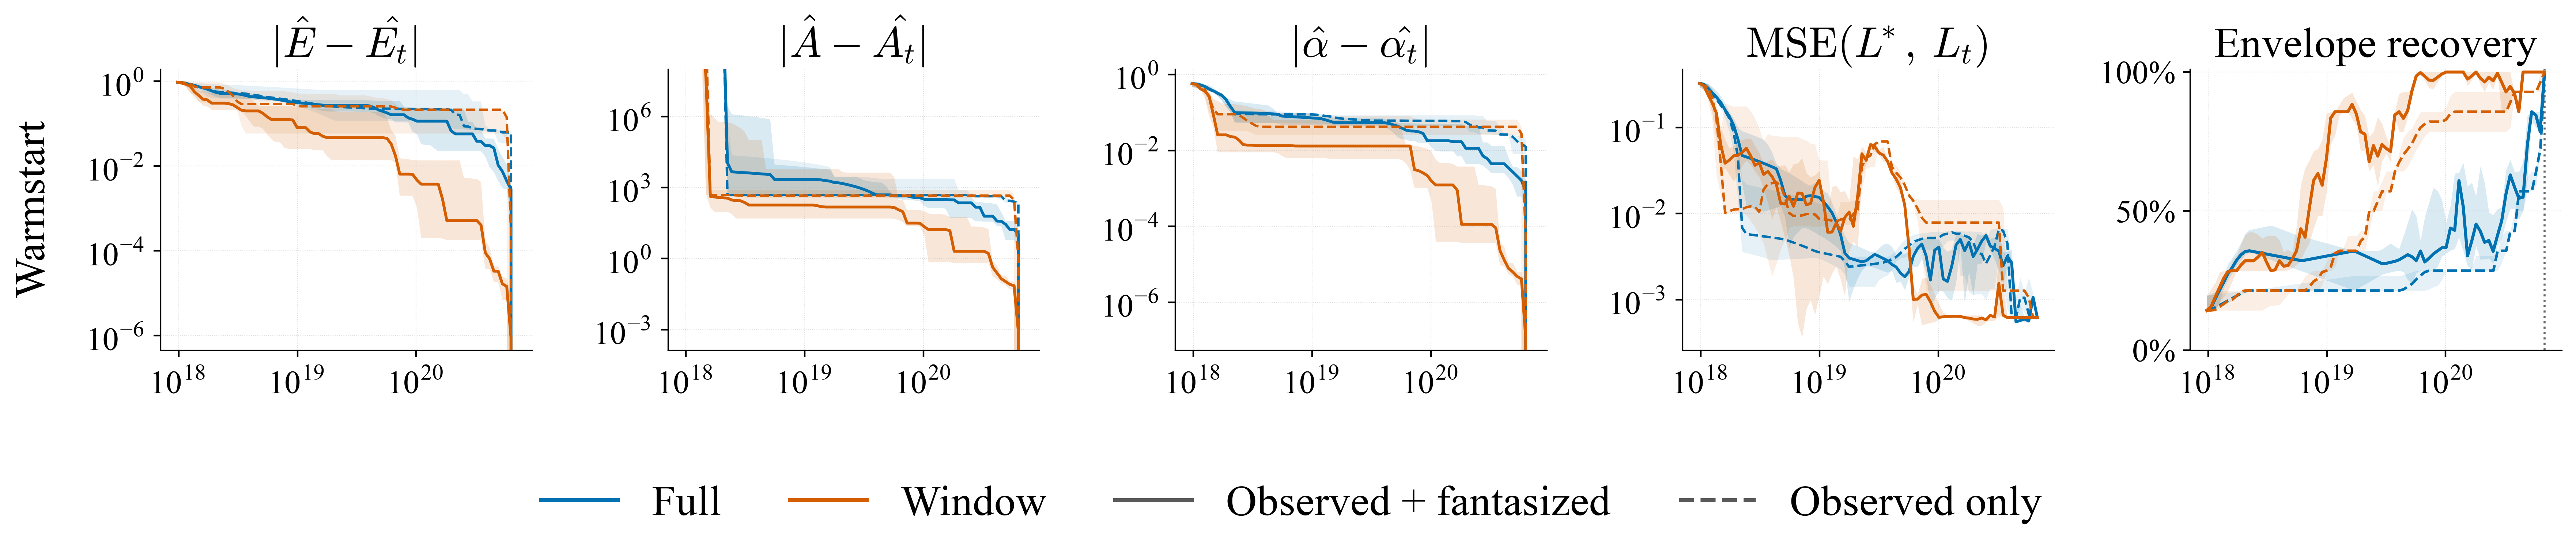

In [24]:
name = "L(C)"
ncols = COEF_COLS + 2
fig_warm, ax_warm = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))

# plot_row reads params from FORMS[name]; warmstart uses the same L0 coefficients
_forms_lc = FORMS["L(C)"]
FORMS["L(C)"] = CFG_LC_WARM
plot_row(ax_warm, name, PREP_LC_WARM, show_mse_env_titles=True, show_xlabel=True, make_xlabel_white=True)
FORMS["L(C)"] = _forms_lc

ax_warm[0].annotate("Warmstart", xy=(-0.34, 0.5), xycoords="axes fraction",
                    rotation=90, va="center", ha="center")
fig_warm.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
                ncol=len(LEGEND_HANDLES), frameon=False, bbox_to_anchor=(0.5, -0.13),
                handlelength=1.8, columnspacing=1.6)
fig_warm.tight_layout()
savefig_cropped_bottom(fig_warm, OUT_DIR / "fig_recovery_LC_warmstart.pdf", crop_bottom_inches=0.8, pad_inches=0.0)
# fig_warm.savefig(OUT_DIR / "fig_recovery_LC_warmstart.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()

## Step-law

In [25]:
DATASET   = "steplaw_dense"
CSV       = REPO / "data" / "steplaw" / "preprocessed" / "steplaw_dense.csv"
df = pd.read_csv(CSV); df["C"] = 6.0 * df["N"] * df["D"]
print("grid points:", len(df), "| C range:", f"{df['C'].min():.2e}", "–", f"{df['C'].max():.2e}")

grid points: 1911 | C range: 5.15e+18 – 3.67e+20


In [26]:
# df

In [27]:
ABL_STEPLAW = EXP / "analysis" / "_ablation_cache" / "ablation_datasets" / "runs"

CFG_LC_STEPLAW = dict(form="L0", run_dir=ABL_STEPLAW, title=r"$L(C)$",
                      params=["L0", "A", "alpha"], arms=arms("full", "window"),
                      split_axis="C", held_out_frac=0.5)

PREP_LC_STEPLAW = prepare(CFG_LC_STEPLAW)
print("L(C) steplaw:", (f"live ({len(PREP_LC_STEPLAW['seeds'])} seeds, "
                        f"{len(PREP_LC_STEPLAW['pool']['PSET'])} envelope pts, "
                        f"{len(PREP_LC_STEPLAW['pool']['held_front'])} held-out frontier pts)"
                        if PREP_LC_STEPLAW else "placeholder (no runs found)"))

L(C) steplaw: live (10 seeds, 6 envelope pts, 1 held-out frontier pts)


In [41]:
PREP_LC_STEPLAW['pool']

{'pool_df':               N             D        lr  gbsz      loss             C
 0     214663680  100000000000  0.000345   736  2.413517  1.287982e+20
 1     429260800   50000000000  0.005524   736  2.288173  1.287782e+20
 2     268304384   80000000000  0.000345   736  2.351091  1.287861e+20
 3     429260800   50000000000  0.002762   736  2.276773  1.287782e+20
 4     429260800   50000000000  0.000488  1024  2.298171  1.287782e+20
 ...         ...           ...       ...   ...       ...           ...
 1906  268304384   25000000000  0.002760   128  2.422707  4.024566e+19
 1907  214663680   20000000000  0.007810    64  2.526995  2.575964e+19
 1908  536872960   50000000000  0.001950   256  2.220808  1.610619e+20
 1909  268304384   25000000000  0.000977  1024  2.452264  4.024566e+19
 1910  268304384   25000000000  0.000977   192  2.397802  4.024566e+19
 
 [1864 rows x 6 columns],
 'held_df':                N            D        lr  gbsz      loss             C
 935   1073741824  56900000

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


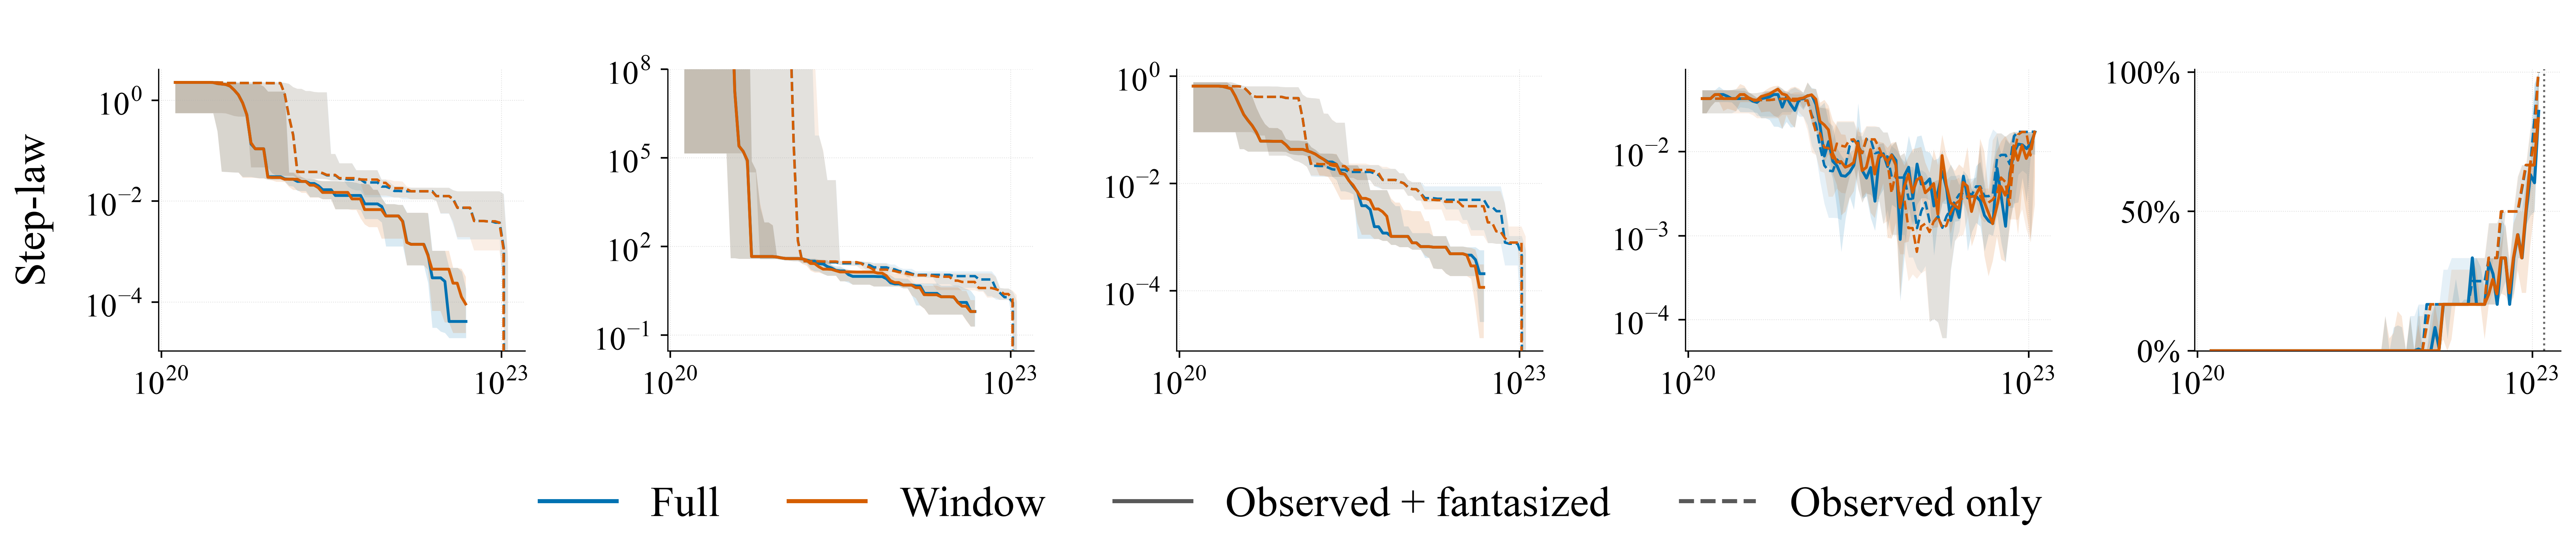

In [30]:
name = "L(C)"
ncols = COEF_COLS + 2
fig_step, ax_step = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))

_forms_lc = FORMS["L(C)"]
FORMS["L(C)"] = CFG_LC_STEPLAW
plot_row(ax_step, name, PREP_LC_STEPLAW, show_mse_env_titles=True, show_xlabel=True, make_xlabel_white=True, make_title_white=True)
FORMS["L(C)"] = _forms_lc

ax_step[0].annotate("Step-law", xy=(-0.34, 0.5), xycoords="axes fraction",
                    rotation=90, va="center", ha="center")
fig_step.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
                ncol=len(LEGEND_HANDLES), frameon=False, bbox_to_anchor=(0.5, -0.13),
                handlelength=1.8, columnspacing=1.6)
fig_step.tight_layout()
# fig_step.savefig(OUT_DIR / "fig_recovery_LC_steplaw.pdf", bbox_inches="tight", pad_inches=0.0)
savefig_cropped_bottom(fig_step, OUT_DIR / "fig_recovery_LC_steplaw.pdf", crop_bottom_inches=0.8, pad_inches=0.0)
plt.show()

## Porian data

In [31]:
DATASET   = "porian_main_stable_rw"
CSV       = REPO / "data" / "porian" / "preprocessed" / "porian_main_stable_rw.csv"
df = pd.read_csv(CSV); df["C"] = 6.0 * df["N"] * df["D"]
print("grid points:", len(df), "| C range:", f"{df['C'].min():.2e}", "–", f"{df['C'].max():.2e}")

grid points: 566 | C range: 3.21e+15 – 5.86e+18


In [32]:
df

,N,D,lr,gbsz,loss,C
0,28670000.0,5.734236e+08,0.00075,8.0,4.383505,9.864033e+16
1,28670000.0,5.734236e+08,0.00150,8.0,4.400314,9.864033e+16
2,28670000.0,5.734236e+08,0.00300,8.0,4.389921,9.864033e+16
3,28670000.0,5.734236e+08,0.00600,8.0,4.400928,9.864033e+16
4,28670000.0,5.734236e+08,0.01200,8.0,4.418782,9.864033e+16
...,...,...,...,...,...,...
561,108500000.0,2.179990e+09,0.00150,512.0,3.621266,1.419173e+18
562,108500000.0,2.179990e+09,0.00300,512.0,3.586426,1.419173e+18
563,108500000.0,2.179990e+09,0.00600,512.0,3.589592,1.419173e+18
564,108500000.0,2.179990e+09,0.01200,512.0,3.621576,1.419173e+18


In [33]:
ABL_PORIAN = EXP / "analysis" / "_ablation_cache" / "ablation_datasets" / "runs"

CFG_LC_PORIAN = dict(form="L0", run_dir=ABL_PORIAN, title=r"$L(C)$",
                     params=["L0", "A", "alpha"], arms=arms("full", "w20"),
                     split_axis="C", held_out_frac=0.5)

PREP_LC_PORIAN = prepare(CFG_LC_PORIAN)
print("L(C) porian:", (f"live ({len(PREP_LC_PORIAN['seeds'])} seeds, "
                       f"{len(PREP_LC_PORIAN['pool']['PSET'])} envelope pts, "
                       f"{len(PREP_LC_PORIAN['pool']['held_front'])} held-out frontier pts)"
                       if PREP_LC_PORIAN else "placeholder (no runs found)"))

L(C) porian: live (10 seeds, 11 envelope pts, 4 held-out frontier pts)


In [35]:
PREP_LC_PORIAN['pool']['held_front']

,N,D,lr,gbsz,loss,C
469,220900000.0,4.418372e+09,0.0015,32.0,3.466810,5.856110e+18
480,220900000.0,4.419486e+09,0.0030,128.0,3.328997,5.857586e+18
532,220900000.0,4.423942e+09,0.0030,512.0,3.317544,5.863493e+18
163,220900000.0,4.424466e+09,0.0030,256.0,3.311077,5.864188e+18


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


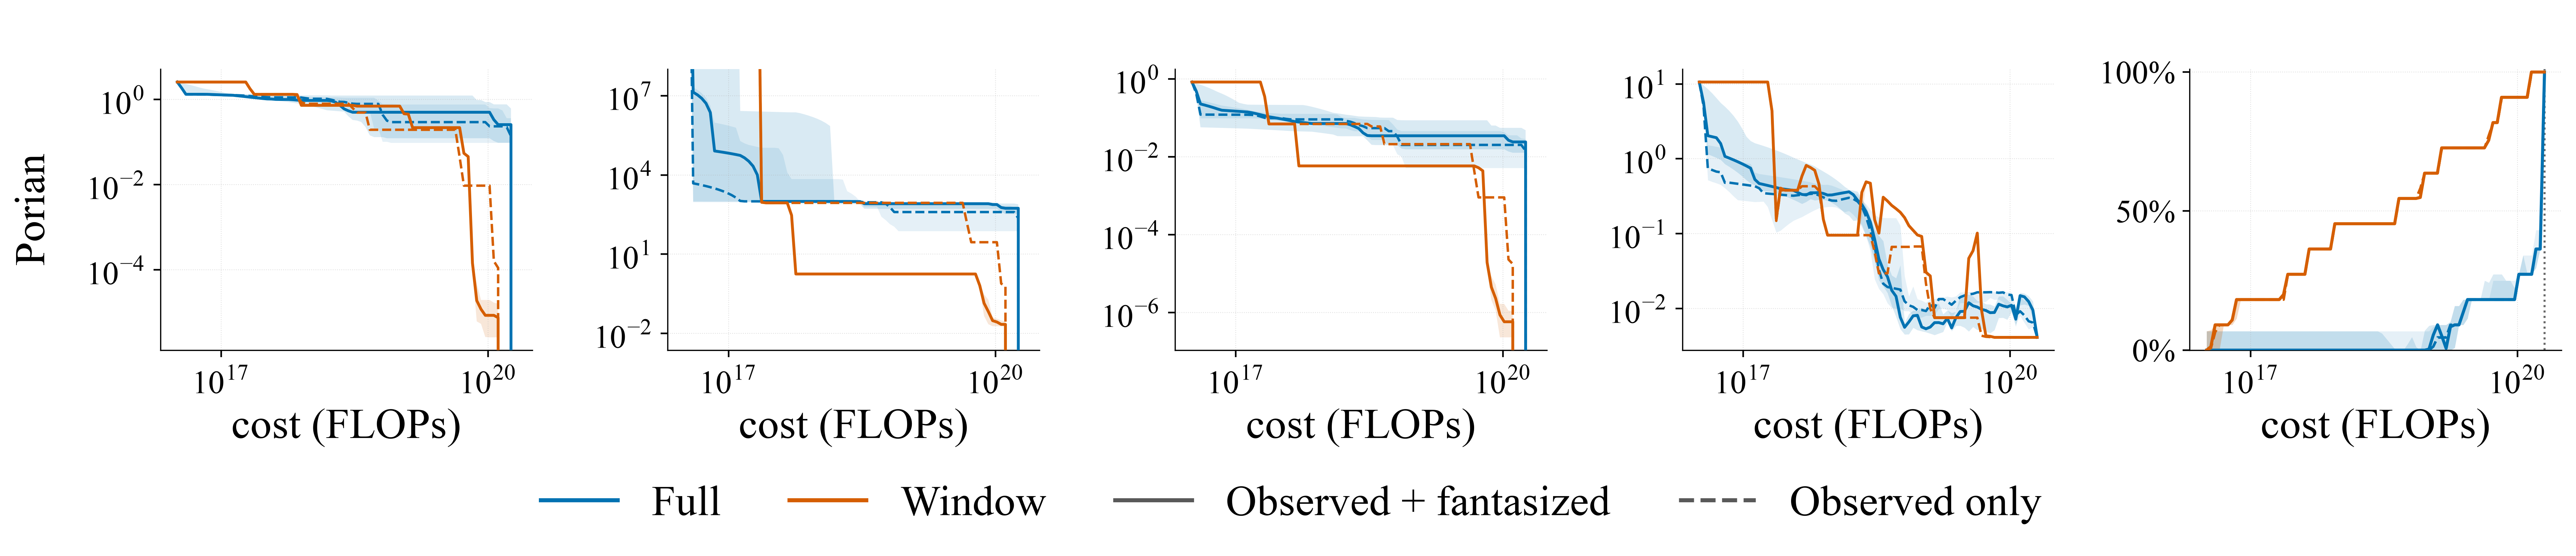

In [34]:
name = "L(C)"
ncols = COEF_COLS + 2
fig_por, ax_por = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))

_forms_lc = FORMS["L(C)"]
FORMS["L(C)"] = CFG_LC_PORIAN
plot_row(ax_por, name, PREP_LC_PORIAN, show_mse_env_titles=True, show_xlabel=True, make_title_white=True)
FORMS["L(C)"] = _forms_lc

ax_por[0].annotate("Porian", xy=(-0.34, 0.5), xycoords="axes fraction",
                   rotation=90, va="center", ha="center")
fig_por.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
               ncol=len(LEGEND_HANDLES), frameon=False, bbox_to_anchor=(0.5, -0.13),
               handlelength=1.8, columnspacing=1.6)
fig_por.tight_layout()
fig_por.savefig(OUT_DIR / "fig_recovery_LC_porian.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()

## OELLM multilingual

In [74]:
DATASET   = "oellm_multilingual"
CSV       = REPO / "data" / "oellm_multilingual" / "preprocessed" / "oellm_multilingual.csv"
df = pd.read_csv(CSV); df["C"] = 6.0 * df["N"] * df["D"]
print("grid points:", len(df), "| C range:", f"{df['C'].min():.2e}", "–", f"{df['C'].max():.2e}")

grid points: 332 | C range: 7.40e+18 – 2.27e+21


In [75]:
ABL_MULTILING = EXP / "analysis" / "_ablation_cache" / "ablation_datasets" / "runs"

CFG_LC_MULTILING = dict(form="L0", run_dir=ABL_MULTILING, title=r"$L(C)$",
                        params=["L0", "A", "alpha"], arms=arms("full", "window"),
                        split_axis="C", held_out_frac=0.5)

PREP_LC_MULTILING = prepare(CFG_LC_MULTILING)
print("L(C) oellm_multilingual:", (f"live ({len(PREP_LC_MULTILING['seeds'])} seeds, "
                                  f"{len(PREP_LC_MULTILING['pool']['PSET'])} envelope pts, "
                                  f"{len(PREP_LC_MULTILING['pool']['held_front'])} held-out frontier pts)"
                                  if PREP_LC_MULTILING else "placeholder (no runs found)"))

L(C) oellm_multilingual: live (10 seeds, 14 envelope pts, 2 held-out frontier pts)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


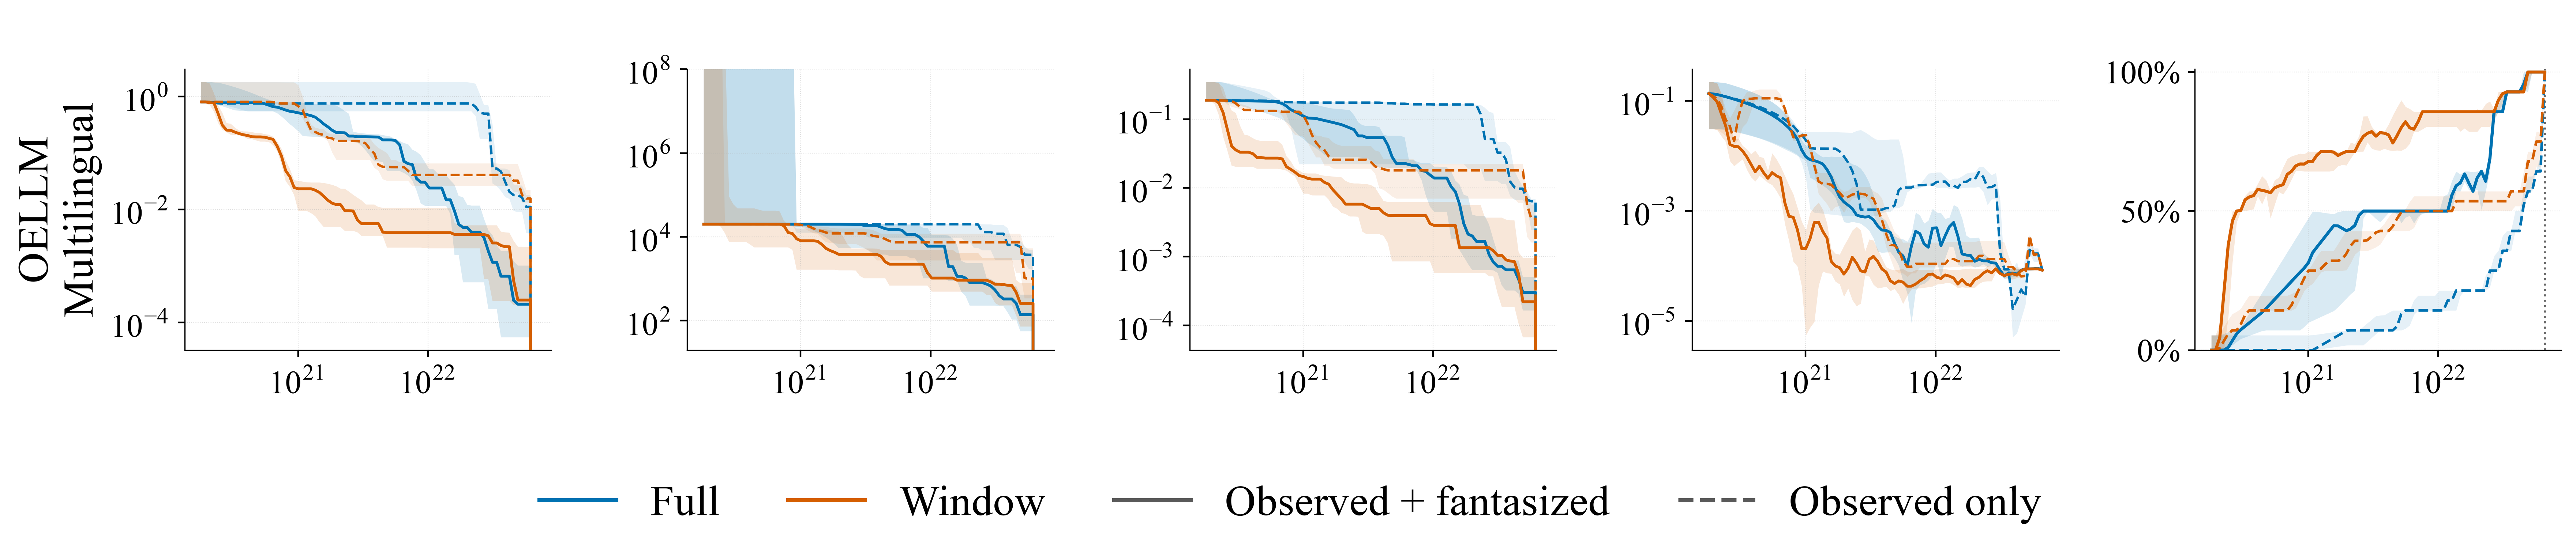

In [80]:
name = "L(C)"
ncols = COEF_COLS + 2
fig_ml, ax_ml = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))

_forms_lc = FORMS["L(C)"]
FORMS["L(C)"] = CFG_LC_MULTILING
plot_row(ax_ml, name, PREP_LC_MULTILING, show_mse_env_titles=True, show_xlabel=True, make_xlabel_white=True, make_title_white=True)
FORMS["L(C)"] = _forms_lc

ax_ml[0].annotate("OELLM\nMultilingual", xy=(-0.34, 0.5), xycoords="axes fraction",
                  rotation=90, va="center", ha="center")
fig_ml.legend(LEGEND_HANDLES, [h.get_label() for h in LEGEND_HANDLES], loc="lower center",
              ncol=len(LEGEND_HANDLES), frameon=False, bbox_to_anchor=(0.5, -0.13),
              handlelength=1.8, columnspacing=1.6)
fig_ml.tight_layout()
# fig_ml.savefig(OUT_DIR / "fig_recovery_LC_oellm_multilingual.pdf", bbox_inches="tight", pad_inches=0.0)
savefig_cropped_bottom(fig_ml, OUT_DIR / "fig_recovery_LC_oellm_multilingual.pdf", crop_bottom_inches=0.8, pad_inches=0.0)
plt.show()

In [40]:
PREP_LC_STEPLAW.keys()

dict_keys(['FORM', 'hist', 'seeds', 'arms', 'pool', 'val_ref', 'init_info'])

## Acquisition function ablation (window, oellm-english)
Compare EI / PI / LCB window arms on `oellm_english`; obs+fantasized curves only.


In [ ]:
AF_EI, AF_PI, AF_LCB = "#D55E00", "#3a86ff", "#588157"   # blue, orange, green

def ablation_arms(ei_c, pi_c, lcb_c):
    return {"ei":  dict(fn="af_ei",  color=ei_c,  label="EI"),
            "pi":  dict(fn="af_pi",  color=pi_c,  label="PI"),
            "lcb": dict(fn="af_lcb", color=lcb_c, label="LCB")}

def prepare_ablation(cfg, ref_arm="ei"):
    """Load multiple ablation arms; intersect seeds across all of them."""
    form_name, run_dir, A = cfg["form"], cfg["run_dir"], cfg["arms"]
    FORM = PARAMETRIC_FORMS[form_name]
    hist, refs, seeds_ok = {a: {} for a in A}, {a: {} for a in A}, {a: [] for a in A}
    for a, ac in A.items():
        for s in SEEDS:
            d = latest(run_dir, ac["fn"], form_name, s)
            if d is None:
                continue
            hist[a][s] = pd.read_parquet(d / "history.parquet")
            hist[a][s].attrs["run_dir"] = str(d)
            refs[a][s] = json.loads((d / "ref_fits.json").read_text())
            seeds_ok[a].append(s)
    seeds = sorted(set.intersection(*[set(seeds_ok[a]) for a in A]))
    if not seeds:
        return None

    pool = build_pool(cfg)
    val_ref = refs[ref_arm][seeds[0]]["validation"]["interpretable"]

    init_info = {}
    pset = set(pool["PSET"])
    for s in seeds:
        row0 = hist[ref_arm][s].iloc[0]
        iset = set(int(i) for i in row0["acquired_idx"]) - {int(row0["new_idx"])}
        idf = df.loc[df.index.intersection(sorted(iset))]
        p, _ = build_fit(idf, form_name=form_name, y_name="loss", fit_quality="dense")
        init_info[s] = dict(
            compute=float(idf["C"].sum()),
            interp=FORM.interpretable(np.asarray(p, float)),
            mse=mse_on_frontier(pool["held_front"], FORM, np.asarray(p, float)),
            env_pct=len(pset & iset) / len(pset) * 100.0,
        )

    for a in A:
        for s in seeds:
            hist[a][s]["law_mse_obs_only_held_out"] = [
                mse_on_frontier(pool["held_front"], FORM, np.asarray(pp, float))
                for pp in hist[a][s]["obs_only_params"]]

    return dict(FORM=FORM, hist=hist, seeds=seeds, arms=A, pool=pool,
                val_ref=val_ref, init_info=init_info, ref_arm=ref_arm)


def _log_x_decades(ax):
    """Label every power of 10 on a log-scaled x-axis (e.g. 10^20 … 10^23)."""
    import matplotlib.ticker as mticker
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0, subs=(1.0,), numticks=30))
    ax.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0, labelOnlyBase=True))
    ax.xaxis.set_minor_locator(mticker.NullLocator())


def plot_ablation(axes_row, name, prep, show_mse_env_titles, show_xlabel, show_xlabel_loc=0,
                  make_xlabel_white=False, make_title_white=False):
    """AF comparison strip: obs+fantasized curves only (one solid line per arm)."""
    import matplotlib.ticker as mticker
    from matplotlib.ticker import LogLocator

    cfg = FORMS[name]
    coef_axes, ax_mse, ax_env = axes_row[:COEF_COLS], axes_row[-2], axes_row[-1]

    if prep is None:
        for ax, cn in zip(coef_axes, cfg["params"]):
            ax.set_title(PLABEL[cn])
        if make_title_white:
            for ax in coef_axes:
                ax.title.set_color("white")
        if show_mse_env_titles:
            ax_mse.set_title(MSE_LABEL)
            ax_env.set_title(ENV_LABEL)
        for ax in axes_row:
            ax.text(0.5, 0.5, "runs pending", transform=ax.transAxes, ha="center", va="center",
                    color="0.6", style="italic")
            ax.set_xticks([])
            ax.set_yticks([])
            if show_xlabel:
                ax.set_xlabel(X_LABEL)
        return

    seeds, A, pool = prep["seeds"], prep["arms"], prep["pool"]

    for ax, cn in zip(coef_axes, cfg["params"]):
        anc = regret_anchor(prep, cn)
        for a, ac in A.items():
            C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], f"regret_val_{cn}",
                                            anchors=anc, abs_first=True)
            ax.plot(C, med, color=ac["color"], lw=1.4, ls="-", zorder=3)
            ax.fill_between(C, lo, hi, color=ac["color"], alpha=0.15, lw=0)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(PLABEL[cn])
        if make_title_white:
            ax.title.set_color("white")
        _log_x_decades(ax)
        ax.yaxis.set_major_locator(LogLocator(base=10.0))
        if cn in COEF_YMAX:
            ax.set_ylim(top=COEF_YMAX[cn])

    anc_mse = mse_anchor(prep)
    for a, ac in A.items():
        C, med, lo, hi = agg_vs_compute([prep["hist"][a][s] for s in seeds], "law_mse_held_out",
                                        running=False, anchors=anc_mse)
        ax_mse.plot(C, med, color=ac["color"], lw=1.4, ls="-", zorder=3)
        ax_mse.fill_between(C, lo, hi, color=ac["color"], alpha=0.15, lw=0)
    ax_mse.set_xscale("log")
    ax_mse.set_yscale("log")
    _log_x_decades(ax_mse)
    ax_mse.yaxis.set_major_locator(LogLocator(base=10.0))
    if show_mse_env_titles:
        ax_mse.set_title(MSE_LABEL)
    if make_title_white:
        ax_mse.title.set_color("white")

    anc_env = env_anchor(prep)
    for a, ac in A.items():
        g, med, q1, q3 = agg_recovery(
            [fantasized_recovery(Path(prep["hist"][a][s].attrs["run_dir"]), prep["hist"][a][s], pool)
             for s in seeds],
            anchors=anc_env,
        )
        ax_env.plot(g, med, color=ac["color"], lw=1.5, ls="-", zorder=3)
        ax_env.fill_between(g, q1, q3, color=ac["color"], alpha=0.15, lw=0)
    ax_env.axvline(pool["pool_total_C"], color="0.4", ls=":", lw=1.0, zorder=2)
    ax_env.set_xscale("log")
    ax_env.set_ylim(0, 101)
    ax_env.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
    _log_x_decades(ax_env)
    if show_mse_env_titles:
        ax_env.set_title(ENV_LABEL)
    if make_title_white:
        ax_env.title.set_color("white")

    for ax in axes_row:
        if show_xlabel:
            ax.set_xlabel(X_LABEL)
            if make_xlabel_white:
                ax.xaxis.label.set_color("white")
        ax.grid(which="major", ls=":", lw=0.4, alpha=0.4)

In [62]:
ABL_ACQ = EXP / "analysis" / "_ablation_cache" / "ablation_acquisition" / "runs"

# ensure oellm-english pool (in case df/DATASET were overwritten by later dataset sections)
DATASET = "oellm_english"
df = pd.read_csv(REPO / "data" / DATASET / "preprocessed" / f"{DATASET}.csv")
df["C"] = 6.0 * df["N"] * df["D"]

CFG_LC_AF = dict(FORMS["L(C)"], run_dir=ABL_ACQ, arms=ablation_arms(AF_EI, AF_PI, AF_LCB))
PREP_LC_AF = prepare_ablation(CFG_LC_AF)
print("L(C) AF ablation:", (f"live ({len(PREP_LC_AF['seeds'])} seeds, "
                            f"{len(PREP_LC_AF['pool']['PSET'])} envelope pts, "
                            f"{len(PREP_LC_AF['pool']['held_front'])} held-out frontier pts)"
                            if PREP_LC_AF else "placeholder (no runs found)"))

L(C) AF ablation: live (10 seeds, 21 envelope pts, 2 held-out frontier pts)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


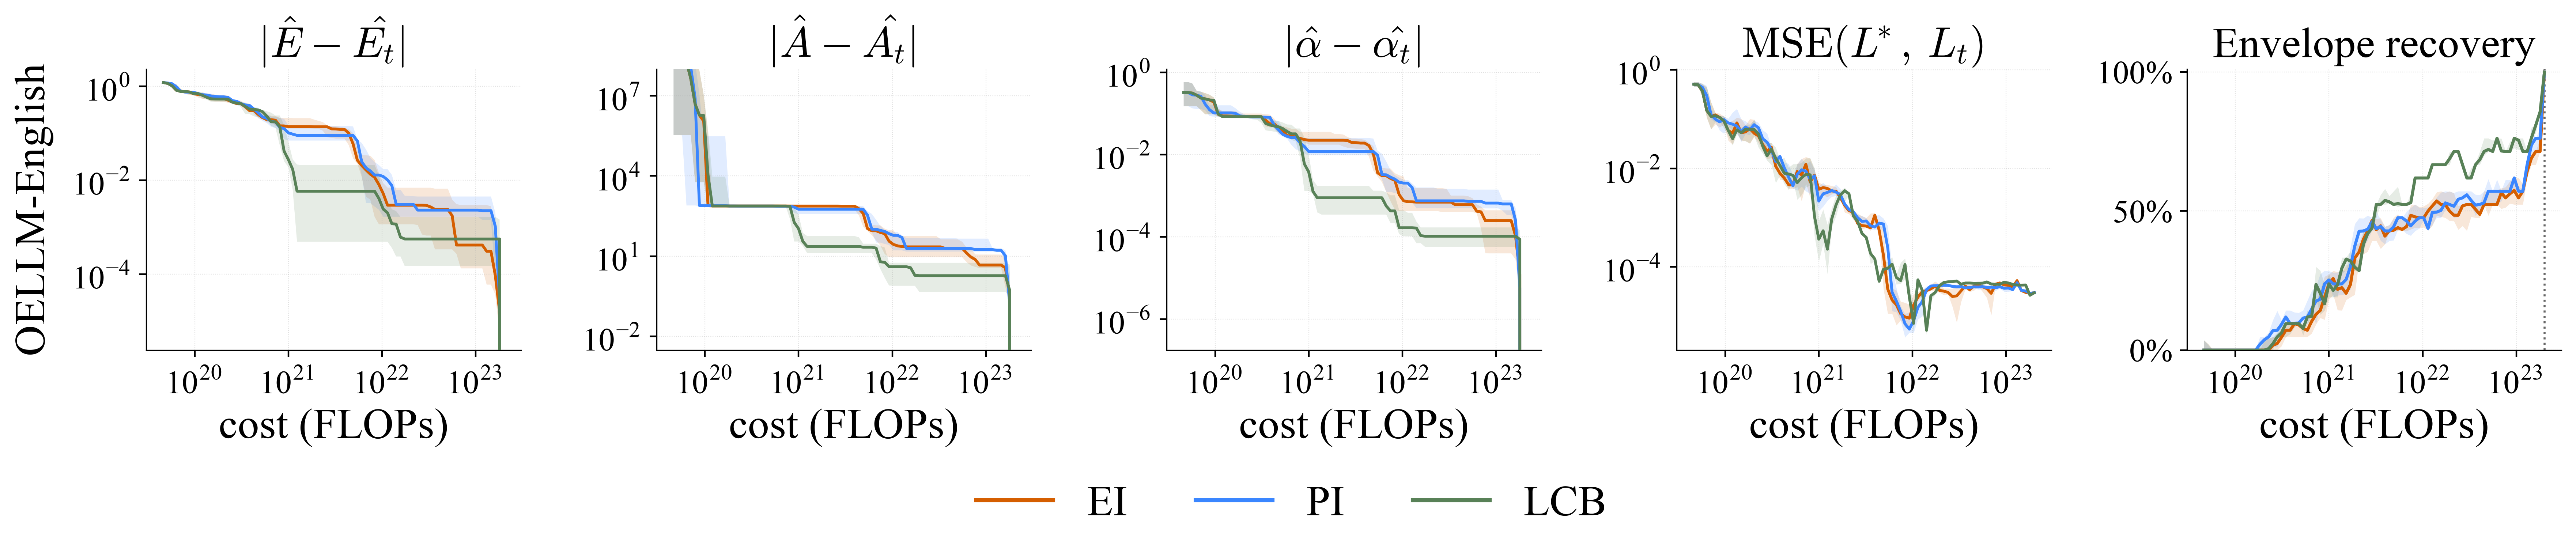

In [63]:
LEGEND_HANDLES_AF = [Line2D([], [], color=AF_EI,  lw=2, ls="-", label="EI"),
                     Line2D([], [], color=AF_PI,  lw=2, ls="-", label="PI"),
                     Line2D([], [], color=AF_LCB, lw=2, ls="-", label="LCB")]

name = "L(C)"
ncols = COEF_COLS + 2
fig_af, ax_af = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))
plot_ablation(ax_af, name, PREP_LC_AF, show_mse_env_titles=True, show_xlabel=True, show_xlabel_loc=0)
ax_af[0].annotate("OELLM-English", xy=(-0.30, 0.5), xycoords="axes fraction",
                  rotation=90, va="center", ha="center")
fig_af.legend(LEGEND_HANDLES_AF, [h.get_label() for h in LEGEND_HANDLES_AF], loc="lower center",
              ncol=len(LEGEND_HANDLES_AF), frameon=False, bbox_to_anchor=(0.5, -0.13),
              handlelength=1.8, columnspacing=1.6)
fig_af.tight_layout()
fig_af.savefig(OUT_DIR / "fig_recovery_LC_af_ablation.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()

## Cost-aware EI ablation (oellm-english)
Compare plain EI (full / window) vs cost-normalized EI (`EI/log(cost)`, `EI/cost`); obs+fantasized curves only.


In [64]:
COST_FULL, COST_WIN, COST_LOG, COST_HARD = "#0072B2", "#D55E00", "#009E73", "#CC79A7"

def cost_aware_arms(full_c, window_c, log_c, hard_c):
    return {"full":     dict(fn="ei_full",     color=full_c,  label="EI full"),
            "window":   dict(fn="ei_window",   color=window_c, label="EI window"),
            "logcost":  dict(fn="ei_logcost",  color=log_c,    label="EI / log(cost)"),
            "hardcost": dict(fn="ei_hardcost", color=hard_c,   label="EI / cost")}

ABL_COST = EXP / "analysis" / "_ablation_cache" / "ablation_cost_aware" / "runs"

DATASET = "oellm_english"
df = pd.read_csv(REPO / "data" / DATASET / "preprocessed" / f"{DATASET}.csv")
df["C"] = 6.0 * df["N"] * df["D"]

CFG_LC_COST = dict(FORMS["L(C)"], run_dir=ABL_COST,
                   arms=cost_aware_arms(COST_FULL, COST_WIN, COST_LOG, COST_HARD))
PREP_LC_COST = prepare_ablation(CFG_LC_COST, ref_arm="full")
print("L(C) cost-aware EI:", (f"live ({len(PREP_LC_COST['seeds'])} seeds, "
                              f"{len(PREP_LC_COST['pool']['PSET'])} envelope pts, "
                              f"{len(PREP_LC_COST['pool']['held_front'])} held-out frontier pts)"
                              if PREP_LC_COST else "placeholder (no runs found)"))

L(C) cost-aware EI: live (10 seeds, 21 envelope pts, 2 held-out frontier pts)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


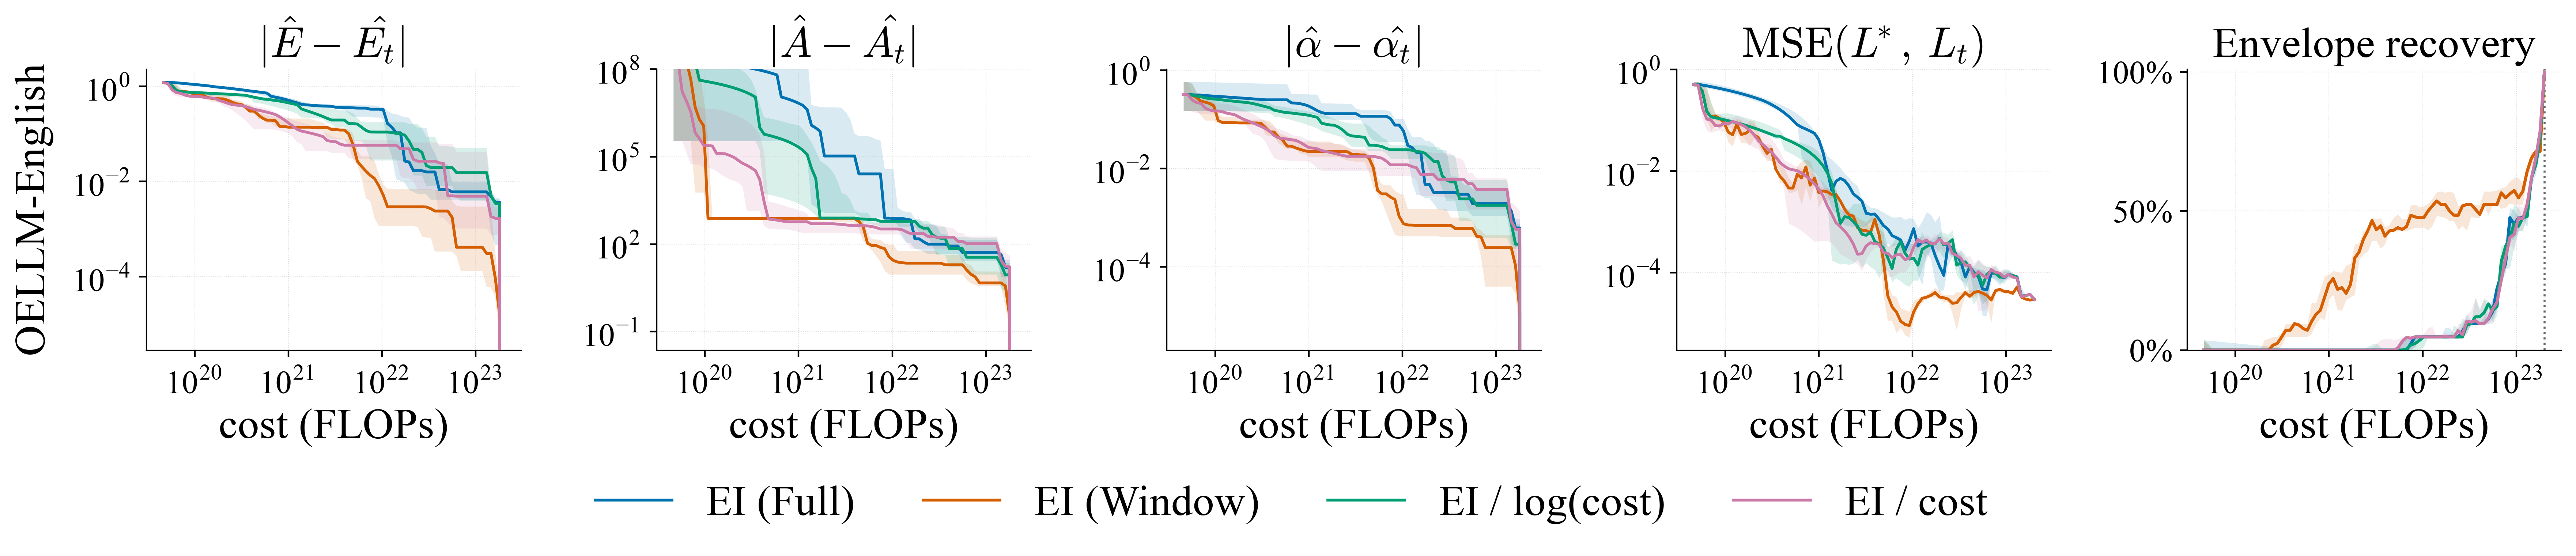

In [66]:
LEGEND_HANDLES_COST = [
    Line2D([], [], color=COST_FULL, lw=1.4, ls="-", label="EI (Full)"),
    Line2D([], [], color=COST_WIN,  lw=1.4, ls="-", label="EI (Window)"),
    Line2D([], [], color=COST_LOG,  lw=1.4, ls="-", label="EI / log(cost)"),
    Line2D([], [], color=COST_HARD, lw=1.4, ls="-", label="EI / cost"),
]

name = "L(C)"
ncols = COEF_COLS + 2
fig_cost, ax_cost = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))
plot_ablation(ax_cost, name, PREP_LC_COST, show_mse_env_titles=True, show_xlabel=True, show_xlabel_loc=0)
ax_cost[0].annotate("OELLM-English", xy=(-0.30, 0.5), xycoords="axes fraction",
                     rotation=90, va="center", ha="center")
fig_cost.legend(LEGEND_HANDLES_COST, [h.get_label() for h in LEGEND_HANDLES_COST], loc="lower center",
                ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.13),
                handlelength=1.8, columnspacing=1.6)
fig_cost.tight_layout()
fig_cost.savefig(OUT_DIR / "fig_recovery_LC_cost_aware.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()

## GP kernel ablation (oellm-english, window)
Compare GP kernel choices under window BO+EI; obs+fantasized curves only.

In [67]:
K_MATERN, K_LINEAR, K_LINMAT, K_LND = "#0072B2", "#D55E00", "#009E73", "#CC79A7"

def gp_kernel_arms(matern_c, linear_c, linmat_c, lnd_c):
    return {"matern":    dict(fn="k_matern",    color=matern_c, label="Matern"),
            "linear":    dict(fn="k_linear",    color=linear_c, label="Linear"),
            "linmat":    dict(fn="k_linmat",    color=linmat_c, label="Linear + Matern"),
            "lnd_mathp": dict(fn="k_lnd_mathp", color=lnd_c,    label="Linear (N,D) + Matern (HPs)")}

ABL_KERNEL = EXP / "analysis" / "_ablation_cache" / "ablation_gp_kernels" / "runs"

DATASET = "oellm_english"
df = pd.read_csv(REPO / "data" / DATASET / "preprocessed" / f"{DATASET}.csv")
df["C"] = 6.0 * df["N"] * df["D"]

CFG_LC_KERNEL = dict(FORMS["L(C)"], run_dir=ABL_KERNEL,
                     arms=gp_kernel_arms(K_MATERN, K_LINEAR, K_LINMAT, K_LND))
PREP_LC_KERNEL = prepare_ablation(CFG_LC_KERNEL, ref_arm="matern")
print("L(C) GP kernels:", (f"live ({len(PREP_LC_KERNEL['seeds'])} seeds, "
                            f"{len(PREP_LC_KERNEL['pool']['PSET'])} envelope pts, "
                            f"{len(PREP_LC_KERNEL['pool']['held_front'])} held-out frontier pts)"
                            if PREP_LC_KERNEL else "placeholder (no runs found)"))

L(C) GP kernels: live (10 seeds, 21 envelope pts, 2 held-out frontier pts)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


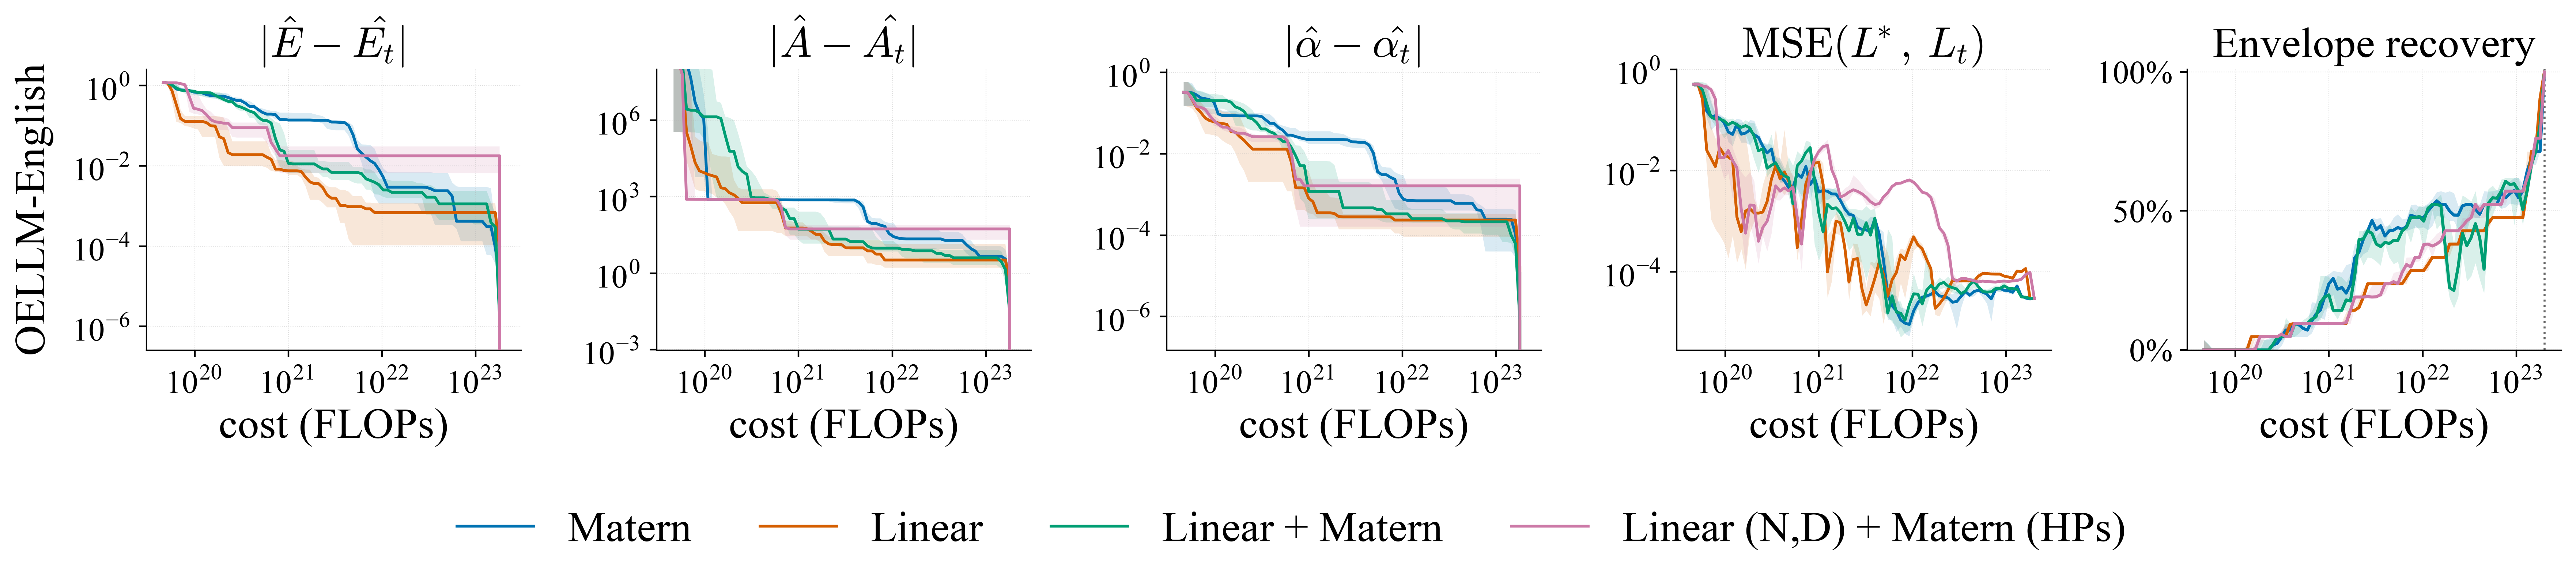

In [72]:
LEGEND_HANDLES_KERNEL = [
    Line2D([], [], color=K_MATERN, lw=1.4, ls="-", label="Matern"),
    Line2D([], [], color=K_LINEAR, lw=1.4, ls="-", label="Linear"),
    Line2D([], [], color=K_LINMAT, lw=1.4, ls="-", label="Linear + Matern"),
    Line2D([], [], color=K_LND,    lw=1.4, ls="-", label="Linear (N,D) + Matern (HPs)"),
]

name = "L(C)"
ncols = COEF_COLS + 2
fig_kern, ax_kern = plt.subplots(1, ncols, figsize=(PANEL_W * ncols, PANEL_H))
plot_ablation(ax_kern, name, PREP_LC_KERNEL, show_mse_env_titles=True, show_xlabel=True, show_xlabel_loc=0)
ax_kern[0].annotate("OELLM-English", xy=(-0.30, 0.5), xycoords="axes fraction",
                    rotation=90, va="center", ha="center")
fig_kern.legend(LEGEND_HANDLES_KERNEL, [h.get_label() for h in LEGEND_HANDLES_KERNEL], loc="lower center",
                ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.18),
                handlelength=1.8, columnspacing=1.6)
fig_kern.tight_layout()
fig_kern.savefig(OUT_DIR / "fig_recovery_LC_gp_kernels.pdf", bbox_inches="tight", pad_inches=0.0)
plt.show()